# Task 1 · Palmer Penguins EDA

**Arrowstack Data Science · Azhar**

Explore sample composition, missingness, morphology, and possible confounding in
the Kaggle Palmer Archipelago dataset. This notebook follows the screenshot's
Kaggle EDA task title. It does not claim compliance with an unseen assignment PDF.

Run cells from top to bottom after installing `requirements-notebooks.txt`.
The source CSV is included; no Kaggle account or network access is required.

[Kaggle dataset](https://www.kaggle.com/datasets/parulpandey/palmer-archipelago-antarctica-penguin-data)
· [Original research data documentation](https://allisonhorst.github.io/palmerpenguins/)

**Questions:** Which species are represented? Which measurements vary by species?
Does the pooled size relationship persist within species? Can island effects be
separated from species? What changes when incomplete records are excluded?

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_all.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 20)

def show_saved_figure(path):
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.imshow(plt.imread(path))
    ax.axis("off")
    fig.tight_layout()
    plt.show()

print("Project root found. Included source data will be used offline.")

Project root found. Included source data will be used offline.


## 1. Inspect the original data

One row is an observation; the simplified file has no unique animal ID.

In [2]:
from task1_eda.analysis import load_data, clean_data, summarize, correlations, outlier_review, run, NUMERIC, CATEGORICAL
raw = load_data()
print("Shape:", raw.shape)
print(raw.head(8).to_string(index=False))
print("\nTypes:\n", raw.dtypes.to_string())
print("\nOriginal missing values:\n", raw.isna().sum().to_string())
print("\nSex values including nonstandard markers:\n", raw.sex.value_counts(dropna=False).to_string())

Shape: (344, 7)
species    island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g    sex
 Adelie Torgersen              39.1             18.7              181.0       3750.0   MALE
 Adelie Torgersen              39.5             17.4              186.0       3800.0 FEMALE
 Adelie Torgersen              40.3             18.0              195.0       3250.0 FEMALE
 Adelie Torgersen               NaN              NaN                NaN          NaN    NaN
 Adelie Torgersen              36.7             19.3              193.0       3450.0 FEMALE
 Adelie Torgersen              39.3             20.6              190.0       3650.0   MALE
 Adelie Torgersen              38.9             17.8              181.0       3625.0 FEMALE
 Adelie Torgersen              39.2             19.6              195.0       4675.0   MALE

Types:
 species               object
island                object
culmen_length_mm     float64
culmen_depth_mm      float64
flipper_length_mm    float64
bo

## 2. Clean with explicit decisions

Normalize `.` as missing sex, lowercase the labels, rename culmen to bill, and
validate positive numeric measurements. Preserve missing measurements rather than
inventing observations. Report identical measurement rows; do not equate them
with duplicate animals. `source_row` is traceability metadata, not a predictor.

In [3]:
clean, audit = clean_data(raw)
print(json.dumps(audit, indent=2))
print("\nDescriptive numeric statistics:\n", clean[NUMERIC].describe().round(2).to_string())
assert len(clean) == len(raw)
assert audit["imputed_values"] == 0

{
  "raw_rows": 344,
  "clean_rows": 344,
  "rows_removed": 0,
  "exact_duplicate_measurement_rows": 0,
  "known_missing_tokens_normalized": {
    "species": 0,
    "island": 0,
    "sex": 1
  },
  "missing_before": {
    "species": 0,
    "island": 0,
    "culmen_length_mm": 2,
    "culmen_depth_mm": 2,
    "flipper_length_mm": 2,
    "body_mass_g": 2,
    "sex": 10
  },
  "missing_after": {
    "source_row": 0,
    "species": 0,
    "island": 0,
    "bill_length_mm": 2,
    "bill_depth_mm": 2,
    "flipper_length_mm": 2,
    "body_mass_g": 2,
    "sex": 11
  },
  "complete_case_rows": 333,
  "imputed_values": 0
}

Descriptive numeric statistics:
        bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
count          342.00         342.00             342.00       342.00
mean            43.92          17.15             200.92      4201.75
std              5.46           1.97              14.06       801.95
min             32.10          13.10             172.00      2700.0

## 3. Reproduce all report files

The same tested Python functions power the command-line workflow and this notebook.

{'rows': 344, 'complete_cases': 333, 'pooled_flipper_mass_r': 0.871201767306011}


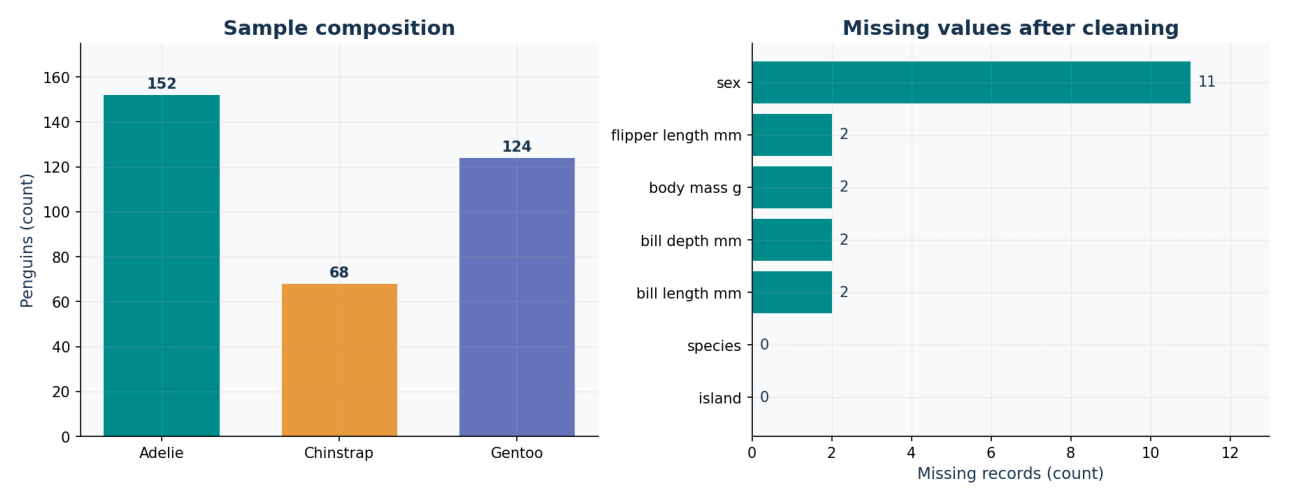

In [4]:
summary_result = run()
print(summary_result)
REPORTS = ROOT / "task1_eda/reports"
show_saved_figure(REPORTS / "figures/01_quality_and_composition.png")

## 4. Compare measurements by species

Show sample size and available mass observations with every group mean.

           rows  measured_mass  mean_mass_g  median_mass_g  mean_flipper_mm  mass_ci_low_g  mass_ci_high_g
species                                                                                                   
Adelie      152            151      3700.66         3700.0           189.95        3628.13         3773.36
Chinstrap    68             68      3733.09         3700.0           195.82        3645.59         3822.43
Gentoo      124            123      5076.02         5000.0           217.19        4990.45         5163.62


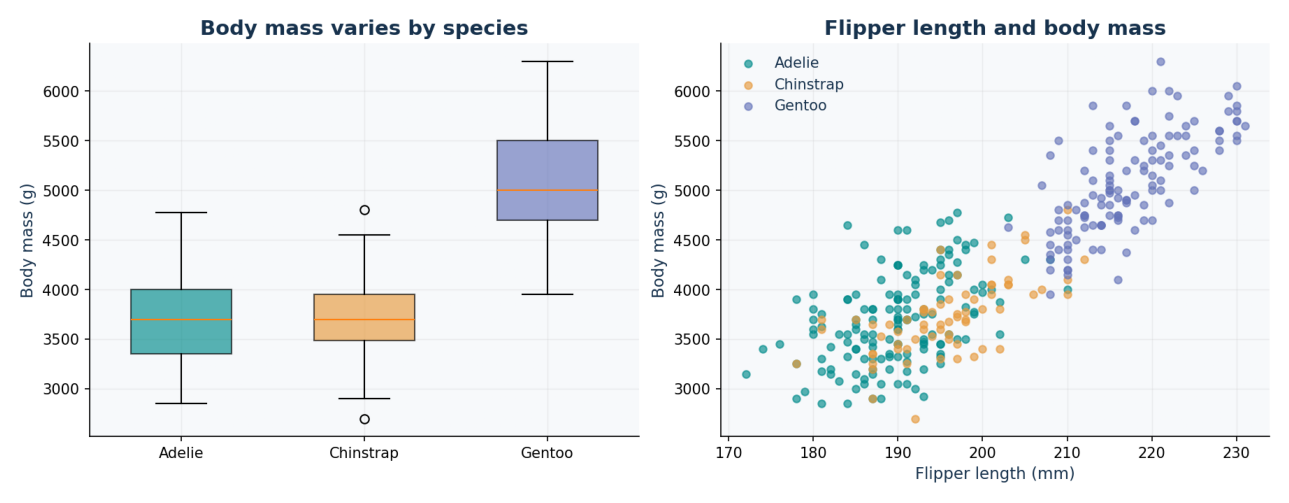

In [5]:
species_summary = summarize(clean)
print(species_summary.round(2).to_string())
show_saved_figure(REPORTS / "figures/02_species_and_measurements.png")

## 5. Check confounding and pooled relationships

Correlation does not establish causation. If species occur on different islands,
an island comparison also changes the species composition. Check the cross-tab
before interpreting geographic differences.

Species × island counts:
 island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         52
Chinstrap       0     68          0
Gentoo        124      0          0

Paired flipper-length/body-mass correlations:
       group  paired_n  pearson_r
All species       342      0.871
     Adelie       151      0.468
  Chinstrap        68      0.642
     Gentoo       123      0.703


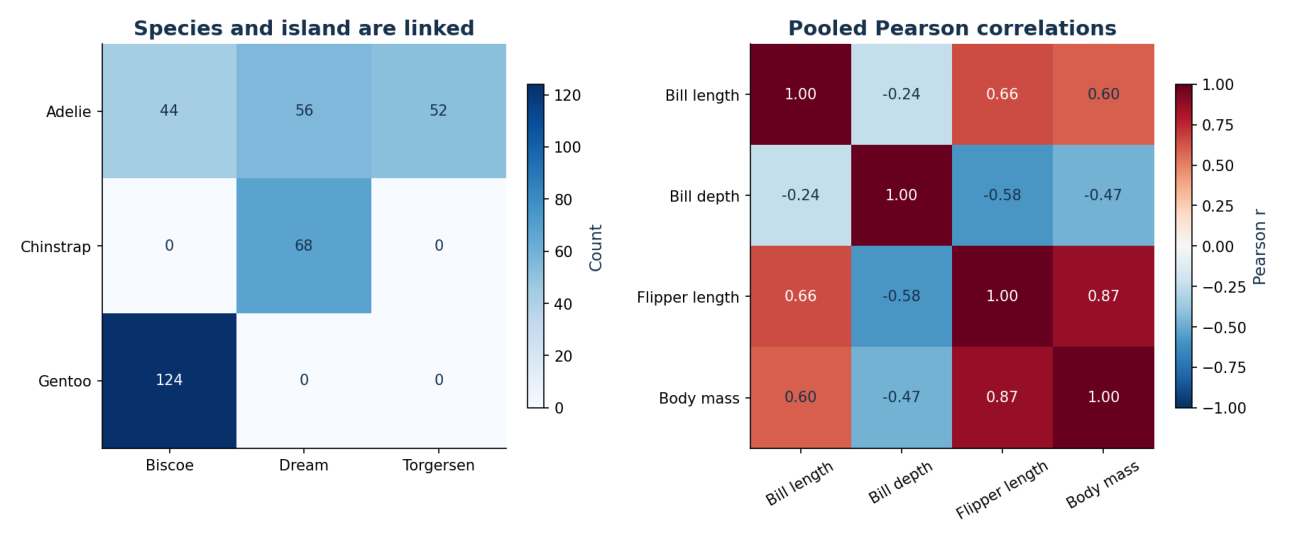

In [6]:
print("Species × island counts:\n", pd.crosstab(clean.species, clean.island).to_string())
print("\nPaired flipper-length/body-mass correlations:\n", correlations(clean).round(3).to_string(index=False))
show_saved_figure(REPORTS / "figures/03_confounding_and_correlations.png")

## 6. Review outliers and uncertainty

Within-species 1.5-IQR flags identify measurements for review, not automatic
deletion. Bootstrap mean intervals use 2,000 resamples and seed 42. They assume
independent observations and do not establish population representativeness.

  species           feature  lower_fence  upper_fence  flagged_rows
   Adelie     bill_depth_mm        15.25        21.25             1
   Adelie flipper_length_mm       172.50       208.50             2
Chinstrap       body_mass_g      2793.75      4643.75             2
   Gentoo    bill_length_mm        38.92        55.92             1


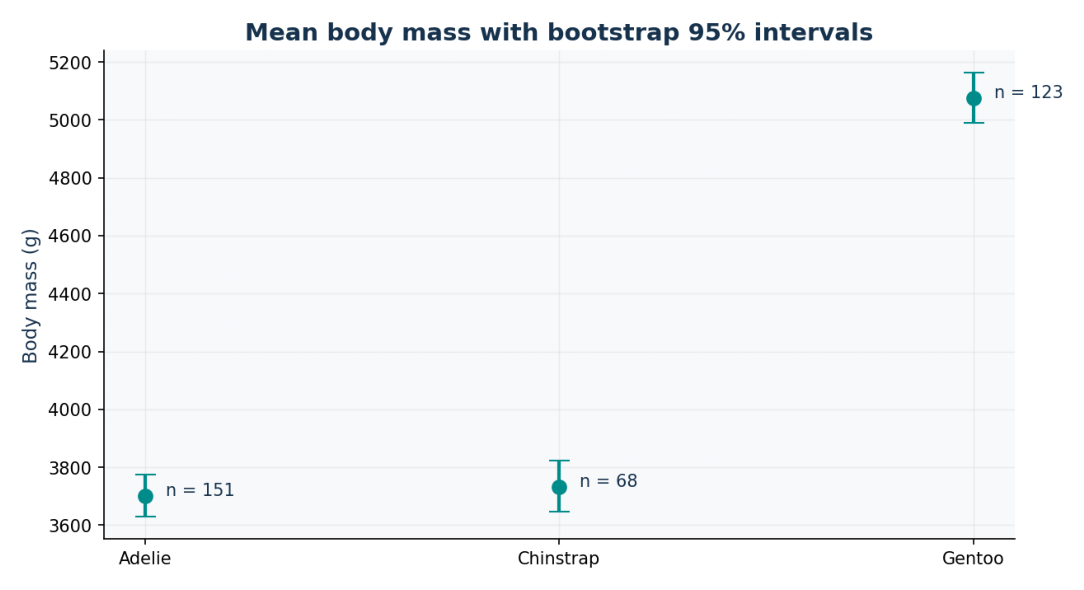

In [7]:
review = outlier_review(clean)
print(review.loc[review.flagged_rows > 0].round(2).to_string(index=False))
show_saved_figure(REPORTS / "figures/04_bootstrap_intervals.png")

## 7. Missingness sensitivity

Compare available mass records with complete cases. A small difference is not proof that data are missing at random.

In [8]:
complete = clean.dropna(subset=NUMERIC + CATEGORICAL)
print(f"Available mass: n={clean.body_mass_g.count()}, mean={clean.body_mass_g.mean():.1f} g")
print(f"Complete cases: n={len(complete)}, mean={complete.body_mass_g.mean():.1f} g")
print(f"Mean difference: {complete.body_mass_g.mean()-clean.body_mass_g.mean():.1f} g")

Available mass: n=342, mean=4201.8 g
Complete cases: n=333, mean=4207.1 g
Mean difference: 5.3 g


## 8. Conclusions and next steps

- Compare body measurements within species; pooled relationships mix species differences.
- Report sample counts, missingness, and uncertainty alongside means.
- Species and island are linked in this sample, so avoid causal geographic claims.
- Investigate unusual measurements using field records before changing them.
- Collect balanced samples and individual identifiers before generalizing beyond this dataset.

Read `reports/final_report.md` for the generated numerical findings,
`docs/data_dictionary.md` for variables, and `../docs/DATA_SOURCES.md` for citations.
This notebook is descriptive EDA; it does not train a prediction model.